# Mini Project 1: Probability, Bayes, and Discrete Random Variables

In [1]:
# Put imports here
import numpy as np
import mp1lib as ml
import scipy as sp
from scipy import stats
import matplotlib as mp
import matplotlib.pyplot as plt
import jupyter as jp

SEED = 733634
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8 = rng.spawn(8)

## Step 1: The sample space and the axioms

C:\Users\aleva\AppData\Local\Temp\ipykernel_43808\3129013377.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(xticklabels = [f"{i:04b} " for i in range(outcomes)],


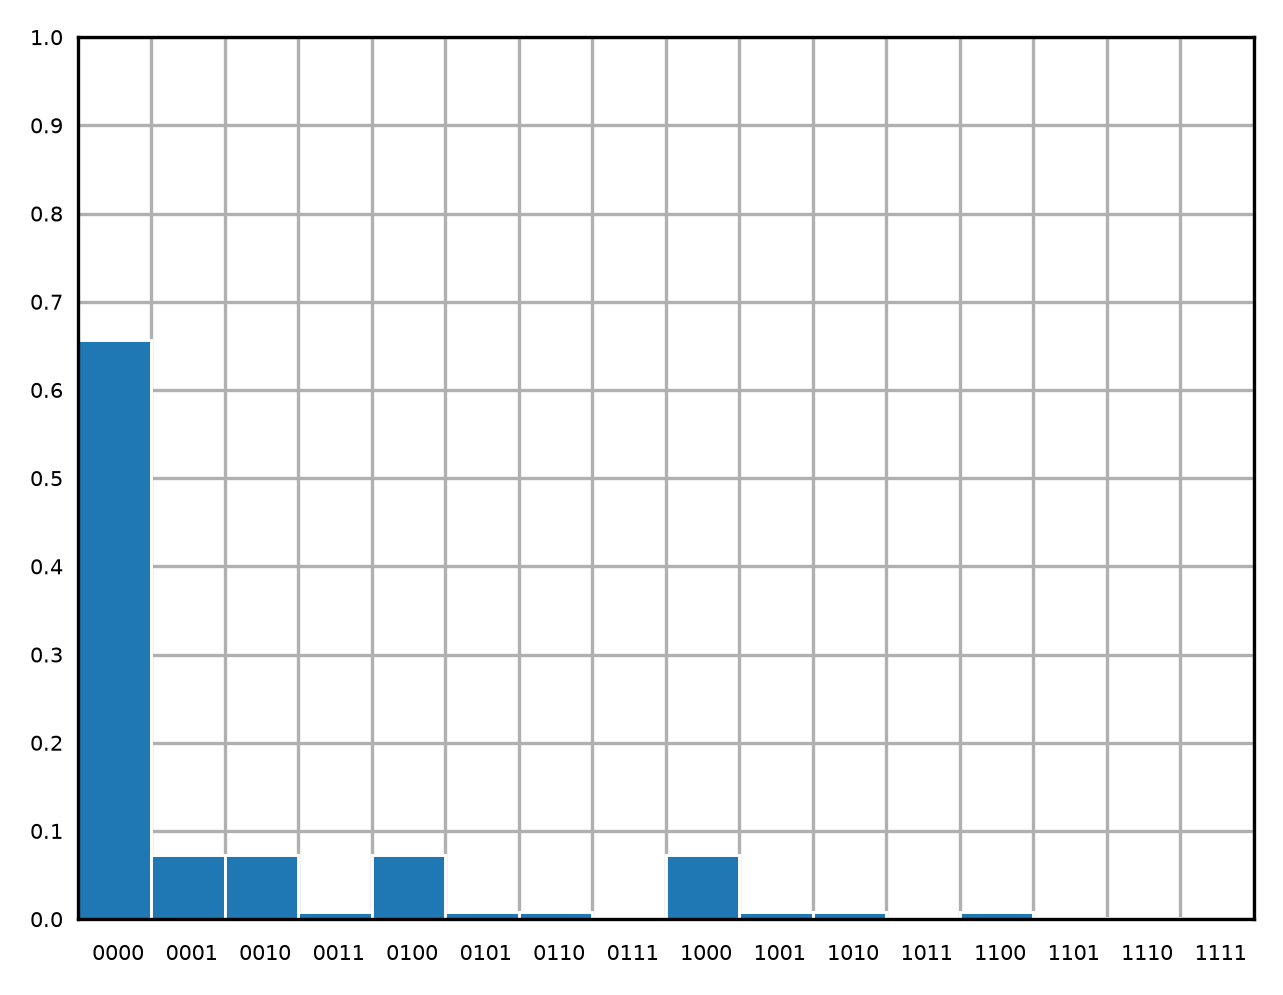

pattern 0000: p = 0.6561
pattern 0001: p = 0.0729
pattern 0010: p = 0.0729
pattern 0011: p = 0.0081
pattern 0100: p = 0.0729
pattern 0101: p = 0.0081
pattern 0110: p = 0.0081
pattern 0111: p = 0.0009
pattern 1000: p = 0.0729
pattern 1001: p = 0.0081
pattern 1010: p = 0.0081
pattern 1011: p = 0.0009
pattern 1100: p = 0.0081
pattern 1101: p = 0.0009
pattern 1110: p = 0.0009
pattern 1111: p = 0.0001

sum = 1.0000


In [2]:
# Question 1

n_bits, p, outcomes = 4, 0.1, 16
patt = np.zeros(outcomes) # pattern[#] = binary packet value with err = 1 and ~err=0

def pattern(n_bits, p, n_errs):
    return (1 - p) ** (n_bits - n_errs) * p ** n_errs

for i in range(outcomes):
    patt[i] = pattern(n_bits, p, i.bit_count())


plt.style.use('_mpl-gallery')

# make data:
x = 0.5 + np.arange(outcomes)
y = patt

# plot
fig, ax = plt.subplots(figsize=(4, 3), dpi=300)

ax.bar(x, y, width=1, edgecolor="white", linewidth=0.7)

ax.set(xticklabels = [f"{i:04b} " for i in range(outcomes)],
       xlim = (0, outcomes), xticks = np.arange(1, outcomes + 1),
       ylim = (0, 1), yticks = np.arange(0, 1.05, 0.1))

ax.tick_params(axis = 'x', pad = 6, labelsize = 5)
ax.tick_params(axis = 'y', labelsize = 5)
for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')

plt.show()

for i in range(outcomes):
    print(f"pattern {i:04b}: p = {patt[i]:.4f}")
print(f"\nsum = {np.sum(patt):.4f}")

In [3]:
# Question 2

P_A = 1 - sp.stats.binom.pmf(0, 2, p)
P_B = sp.stats.binom.pmf(2, n_bits, p)
P_C = p

print("Theoretical:")
print(f"P(A) = {P_A:.4f}")
print(f"P(B) = {P_B:.4f}")
print(f"P(B) = {P_C:.4f}")

Theoretical:
P(A) = 0.1900
P(B) = 0.0486
P(B) = 0.1000


In [4]:
# Question 3

N = 10 ** 6

P_A_sim = np.mean(ml.packet_errors(N, 2, p, rng_1) > 0)
P_B_sim = np.mean(ml.packet_errors(N, n_bits, p, rng_1) == 2)
P_C_sim = np.mean(ml.packet_errors(N, 1, p, rng_1))

print("Simulation:")
print(f"P(A) \u2248 {P_A_sim:.4f}")
print(f"P(B) \u2248 {P_B_sim:.4f}")
print(f"P(C) \u2248 {P_C_sim:.4f}")

Simulation:
P(A) ≈ 0.1899
P(B) ≈ 0.0480
P(C) ≈ 0.0997


In [5]:
# Question 4

P_AB = P_B - P_B / sp.special.comb(4, 2)
P_BC = p * sp.stats.binom.pmf(1, n_bits-1, p)
P_CA = P_C * P_A
P_ABC = sp.stats.binom.pmf(1, 2, p) * (1-p) * p

bits_in = np.zeros((N, n_bits), int)
bits_out = ml.bsc(bits_in, p, rng_1)
A_arr_err = np.sum(bits_out[:, :2], axis = 1) > 0
B_arr_err = np.sum(bits_out, axis = 1) == 2
C_arr_err = bits_out[:, 3]

P_AB_sim = np.mean(A_arr_err & B_arr_err)
P_BC_sim = np.mean(B_arr_err & C_arr_err)
P_CA_sim = np.mean(C_arr_err & A_arr_err)
P_ABC_sim = np.mean(A_arr_err & B_arr_err & C_arr_err)

print("Theoretical:")
print(f"P(A \u2229 B) = {P_AB:.4f}")
print(f"P(B \u2229 C) = {P_BC:.4f}")
print(f"P(C \u2229 A) = {P_CA:.4f}")
print(f"P(A \u2229 B \u2229 C) = {P_ABC:.4f}\n")

print("Simulation:")
print(f"P(A \u2229 B) \u2248 {P_AB_sim:.4f}")
print(f"P(B \u2229 C) \u2248 {P_BC_sim:.4f}")
print(f"P(C \u2229 A) \u2248 {P_CA_sim:.4f}")
print(f"P(A \u2229 B \u2229 C) \u2248 {P_ABC_sim:.4f}")

Theoretical:
P(A ∩ B) = 0.0405
P(B ∩ C) = 0.0243
P(C ∩ A) = 0.0190
P(A ∩ B ∩ C) = 0.0162

Simulation:
P(A ∩ B) ≈ 0.0405
P(B ∩ C) ≈ 0.0241
P(C ∩ A) ≈ 0.0190
P(A ∩ B ∩ C) ≈ 0.0162


### Inclusion-Exclusion Formulas

$P(A \cup B) = P(A) + P(B) - P(A \cap B)$

$P(A \cup B \cup C) = P(A) + P(B) + P(C) - P(A \cap B) - P(B \cap C) - P(C \cap A) + P(A \cap B \cap C)$

In [6]:
# Question 5

P_ABCU = 1 - sp.stats.binom.pmf(0, 3, p)
P_ABCU_IE = P_A + P_B + P_C - P_AB - P_BC - P_CA + P_ABC

P_ABCU_sim = np.mean(A_arr_err | B_arr_err | C_arr_err)
P_ABCU_sim_IE = P_A_sim + P_B_sim + P_C_sim - P_AB_sim - P_BC_sim - P_CA_sim + P_ABC_sim

print("Theoretical:")
print(f"w/o IE formula: P(A \u222A B \u222A C) = {P_ABCU:.4f}")
print(f"w/  IE formula: P(A \u222A B \u222A C) = {P_ABCU_IE:.4f}\n")

print("Simulation:")
print(f"w/o IE formula: P(A \u222A B \u222A C) \u2248 {P_ABCU_sim:.4f}")
print(f"w/  IE formula: P(A \u222A B \u222A C) \u2248 {P_ABCU_sim_IE:.4f}")

Theoretical:
w/o IE formula: P(A ∪ B ∪ C) = 0.2710
w/  IE formula: P(A ∪ B ∪ C) = 0.2710

Simulation:
w/o IE formula: P(A ∪ B ∪ C) ≈ 0.2712
w/  IE formula: P(A ∪ B ∪ C) ≈ 0.2703


In [7]:
# Question 6

results = [
    (P_A, P_A_sim, "Event A"),
    (P_B, P_B_sim, "Event B"),
    (P_C, P_C_sim, "Event C"),
    (P_AB, P_AB_sim, "Intersect AB"),
    (P_BC, P_BC_sim, "Intersect BC"),
    (P_CA, P_CA_sim, "Intersect CA"),
    (P_ABC, P_ABC_sim, "Intersect ABC"),
    (P_ABCU, P_ABCU_sim, "Union ABC"),
    (P_ABCU_IE, P_ABCU_sim_IE, "Union ABC IE")
]

print(f"{'Event':<16} | {'Simulated':<11} | {'Theoretical':<11} | {'Difference':<11} | {'Std. Error':<11} | <3SE")
print("-" * 80)

for p_theory, p_sim, event in results:
    SE = np.sqrt((p_theory * (1 - p_theory)) / N)
    thresh = 3 * SE
    diff = np.abs(p_sim - p_theory)
    test = diff <= thresh
    
    print(f"{event:<16} | {p_sim:<11.6f} | {p_theory:<11.6f} | {diff:<11.6f} | {SE:<11.6f} | {test}")
    
    assert test, f"{event} variation exceeds standard error parameters."

print("\nAll simulations estimate within 3 standard errors.")


Event            | Simulated   | Theoretical | Difference  | Std. Error  | <3SE
--------------------------------------------------------------------------------
Event A          | 0.189858    | 0.190000    | 0.000142    | 0.000392    | True
Event B          | 0.048042    | 0.048600    | 0.000558    | 0.000215    | True
Event C          | 0.099731    | 0.100000    | 0.000269    | 0.000300    | True
Intersect AB     | 0.040477    | 0.040500    | 0.000023    | 0.000197    | True
Intersect BC     | 0.024092    | 0.024300    | 0.000208    | 0.000154    | True
Intersect CA     | 0.018981    | 0.019000    | 0.000019    | 0.000137    | True
Intersect ABC    | 0.016183    | 0.016200    | 0.000017    | 0.000126    | True
Union ABC        | 0.271215    | 0.271000    | 0.000215    | 0.000444    | True
Union ABC IE     | 0.270264    | 0.271000    | 0.000736    | 0.000444    | True

All simulations estimate within 3 standard errors.


## Step 2: Conditional probability and Bayes

### Question 1.

$P(F|err) = 0.95$

$P(F|err^c) = 0.02$

$P(err) = p$

$P(err^c) = 1-p$

$P(F) = P(F|err) \cdot P(err) + P(F|err^c) \cdot P(err^c)$

$P(err|F) = \frac{P(F|err)P(err)}{P(F)}$

In [8]:
# Question 2: Evaluate the posterior at p = 0.1, p = 0.01, and p = 0.001.

prob_F_err = 0.95
prob_F_errc = 0.02

def posterior(F_err, F_errc, p):
    F = (F_err * p) + (F_errc * (1 - p))
    return (F_err * p) / F

print (f"at p = 0.100: {posterior(prob_F_err, prob_F_errc, 0.1):.3f}")
print (f"at p = 0.010: {posterior(prob_F_err, prob_F_errc, 0.01):.3f}")
print (f"at p = 0.001: {posterior(prob_F_err, prob_F_errc, 0.001):.4f}")

at p = 0.100: 0.841
at p = 0.010: 0.324
at p = 0.001: 0.0454


Text(0, 0.5, 'Posterior')

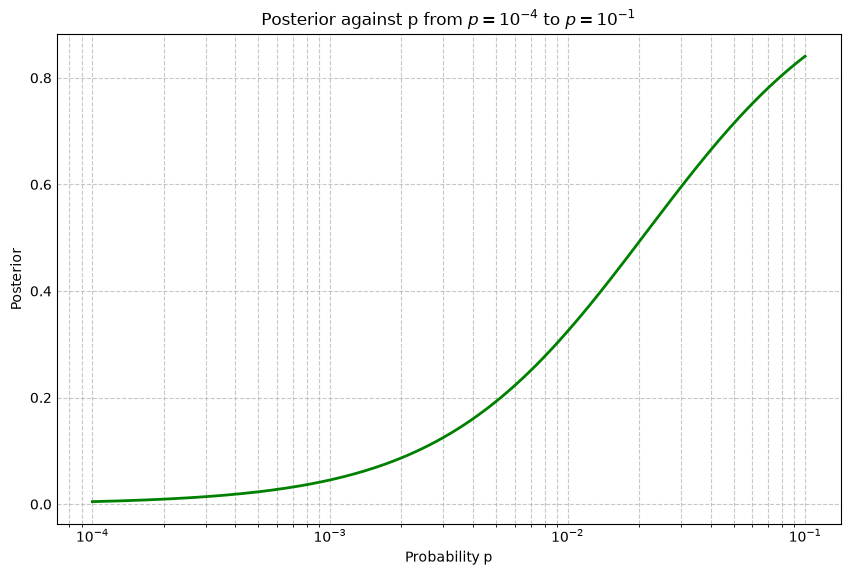

In [9]:
# Question 3: Plot the posterior against p for p from 10^-4 to 10^-1, log spaced, 200 points.

x = np.logspace(-4, -1, 200, True, 10)
y = posterior(prob_F_err, prob_F_errc, x)

plt.figure(figsize = (8, 5))
plt.plot(x, y, label = (r'Posterior against p'), color = 'green', linewidth = 2)
plt.xscale('log')
plt.grid(True, which = 'both', linestyle = '--', alpha = 0.7)
plt.title(r'Posterior against p from $p=10^{-4}$ to $p=10^{-1}$')
plt.xlabel('Probability p')
plt.ylabel('Posterior')

### Question 4: Solve analytically for the p at which the posterior equals 0.5. 

$P(err|F) = \frac{P(F|err)P(err)}{P(F)}$

$P(F) = P(F|err) \cdot P(err) + P(F|err^c) \cdot P(err^c)$

$0.5 = \frac{P(F|err)P(err)}{P(F|err) \cdot P(err) + P(F|err^c) \cdot P(err^c)}$

$P(F|err) \cdot P(err) + P(F|err^c) \cdot (1-P(err)) = 2P(F|err)P(err)$

$P(err)(P(F|err) - P(F|err^c) - 2P(F|err)) = -P(F|err^c)$

$P(err) = \frac{-P(F|err^c)}{P(F|err) - P(F|err^c) - 2P(F|err)}$

$P(err) = \frac{P(F|err^c)}{(P(F|err) + P(F|err^c))}$

At which posterior equals 0.5, p = 0.0206


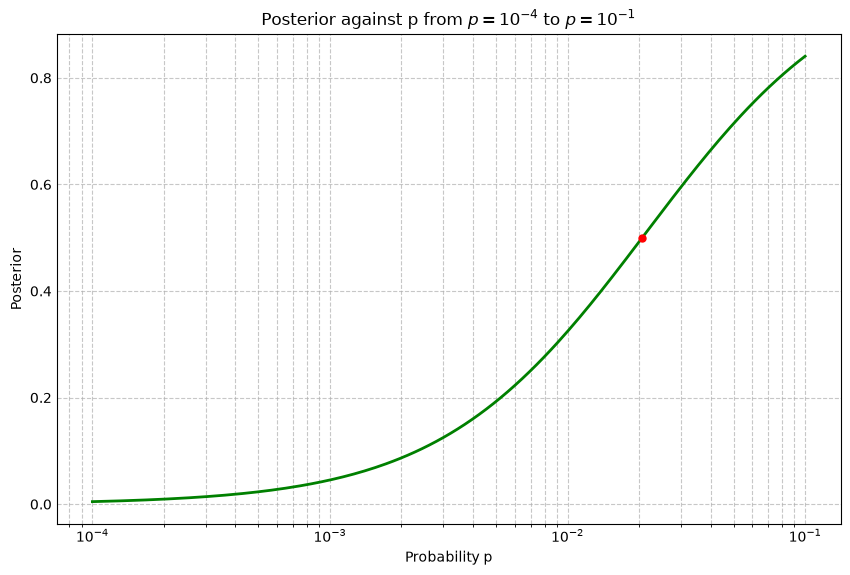

In [10]:
# Report it to three significant figures and mark it on the plot.

x_pdot5 = prob_F_errc / (prob_F_errc + prob_F_err)
print (f"At which posterior equals 0.5, p = {x_pdot5:.3g}")

plt.figure(figsize = (8, 5))
plt.plot(x, y, label = (r'Posterior against p'), color = 'green', linewidth = 2)
plt.xscale('log')
plt.grid(True, which = 'both', linestyle = '--', alpha = 0.7)
plt.title(r'Posterior against p from $p=10^{-4}$ to $p=10^{-1}$')
plt.xlabel('Probability p')
plt.ylabel('Posterior')
plt.plot(x_pdot5, 0.5, 'o', color = 'red', markersize = 5)

In [11]:
# Question 5: Verify that value by Monte Carlo

N_bits = 10 ** 7
p = 0.0206

err = ml.packet_errors(N_bits, 1, p, rng_2)
p_flag = np.where(err, 0.95, 0.02) # defined the conditional probability
flag = rng_2.random(N_bits) < p_flag # implementing the flag circuit

flag_true = np.sum((flag == 1) & (err == 1)) # flag correctly identified error
print (f"Correctly flagged errors:          flag_true = {flag_true}")
flag_tot = np.sum(flag) # total flags on pkt
print (f"Total Flags on pkt:                flag_tot = {flag_tot}")
post = flag_true / flag_tot

print (f"Simulation w/ p = 0.0206:          posterior = {post}")
print (f"Sanity check:                      flag_tot / N_bits = {flag_tot / N_bits}")
print (f"Standard error:                    SE = {np.sqrt((post * (1 - post)) / flag_tot)}")


Correctly flagged errors:          flag_true = 194800
Total Flags on pkt:                flag_tot = 390590
Simulation w/ p = 0.0206:          posterior = 0.49873268644870583
Sanity check:                      flag_tot / N_bits = 0.039059
Standard error:                    SE = 0.000800033272555549


### Question 6:

When a packet is sent with 95% accuracy, it means almost nothing to the error detection circuit, with flag accuracies of 32.4% in a packet with 1% error probability and 4.54% at 0.1% error probability. As the circuit becomes more accurate, the probability of the circuit flagging false-positives becomes higher, and the overall probability of the flags detecting true-positives drops significantly. This creates a scenario where chances of the flags correctly detecting errors become less as the sample size of errors that need to be flagged decrease.

## Step 3: Independence

In [12]:
# Question 1

n_coins, p, outcomes = 2, 0.5, 4

P_E1 = P_E2 = P_E3 = 0
P_E1E2 = P_E2E3 = P_E3E1 = P_E1E2E3 = 0
for i in range(outcomes):
    if i & 1:               P_E1 = P_E1 + pattern(n_coins, p, i.bit_count())
    if (i >> 1) & 1:        P_E2 = P_E2 + pattern(n_coins, p, i.bit_count())
    if ~((i >> 1) ^ i) & 1:    P_E3 = P_E3 + pattern(n_coins, p, i.bit_count())

    if (i >> 1) & i & 1:    P_E1E2 = P_E1E2 + pattern(n_coins, p, i.bit_count())
    if (i >> 1) & i & 1:    P_E2E3 = P_E2E3 + pattern(n_coins, p, i.bit_count())
    if (i >> 1) & i & 1:    P_E3E1 = P_E3E1 + pattern(n_coins, p, i.bit_count())
    if (i >> 1) & i & 1:    P_E1E2E3 = P_E1E2E3 + pattern(n_coins, p, i.bit_count())

P_E1_sim = np.mean(ml.packet_errors(N, 1, p, rng_3))
P_E2_sim = np.mean(ml.packet_errors(N, 1, p, rng_3))
P_E3_sim = np.mean(ml.packet_errors(N, n_coins, p, rng_3) != 1)

P_E1E2_sim = np.mean(ml.packet_errors(N, n_coins, p, rng_3) == 2)
P_E2E3_sim = np.mean(ml.packet_errors(N, n_coins, p, rng_3) == 2)
P_E3E1_sim = np.mean(ml.packet_errors(N, n_coins, p, rng_3) == 2)
P_E1E2E3_sim = np.mean(ml.packet_errors(N, n_coins, p, rng_3) == 2)

print("Theoretical:", " " * 43, "|",
      "Simulation:")
print("-" * 117)

print(f"P(E1) = {P_E1}, P(E2) = {P_E2}, P(E3) = {P_E3}                    |",
      f"P(E1) \u2248 {P_E1_sim:.4f}, P(E2) \u2248 {P_E2_sim:.4f}, P(E3) \u2248 {P_E3_sim:.4f}")
print(" " * 56, "|")

print(f"P(E1 \u2229 E2) = {P_E1E2} | P(E1) x P(E2) = {P_E1 * P_E2}                 |",
      f"P(E1 \u2229 E2) \u2248 {P_E1E2_sim:.4f} | P(E1) x P(E2) \u2248 {P_E1_sim * P_E2_sim:.4f}")
print(f"P(E2 \u2229 E3) = {P_E2E3} | P(E2) x P(E3) = {P_E2 * P_E3}                 |",
      f"P(E2 \u2229 E3) \u2248 {P_E2E3_sim:.4f} | P(E2) x P(E3) \u2248 {P_E2_sim * P_E3_sim:.4f}")
print(f"P(E3 \u2229 E1) = {P_E3E1} | P(E3) x P(E1) = {P_E3 * P_E1}                 |",
      f"P(E3 \u2229 E1) \u2248 {P_E3E1_sim:.4f} | P(E3) x P(E1) \u2248 {P_E3_sim * P_E1_sim:.4f}")
print(" " * 56, "|")

print(f"P(E1 \u2229 E2 \u2229 E3) = {P_E1E2E3} | P(E1) x P(E2) x P(E3) = {P_E1 * P_E2 * P_E3}   |",
      f"P(E1 \u2229 E2 \u2229 E3) \u2248 {P_E1E2E3_sim:.4f} | P(E1) x P(E2) x P(E3) \u2248 {P_E1_sim * P_E2_sim * P_E3_sim:.4f}")

Theoretical:                                             | Simulation:
---------------------------------------------------------------------------------------------------------------------
P(E1) = 0.5, P(E2) = 0.5, P(E3) = 0.5                    | P(E1) ≈ 0.4995, P(E2) ≈ 0.4999, P(E3) ≈ 0.5001
                                                         |
P(E1 ∩ E2) = 0.25 | P(E1) x P(E2) = 0.25                 | P(E1 ∩ E2) ≈ 0.2499 | P(E1) x P(E2) ≈ 0.2497
P(E2 ∩ E3) = 0.25 | P(E2) x P(E3) = 0.25                 | P(E2 ∩ E3) ≈ 0.2496 | P(E2) x P(E3) ≈ 0.2500
P(E3 ∩ E1) = 0.25 | P(E3) x P(E1) = 0.25                 | P(E3 ∩ E1) ≈ 0.2496 | P(E3) x P(E1) ≈ 0.2498
                                                         |
P(E1 ∩ E2 ∩ E3) = 0.25 | P(E1) x P(E2) x P(E3) = 0.125   | P(E1 ∩ E2 ∩ E3) ≈ 0.2499 | P(E1) x P(E2) x P(E3) ≈ 0.1249


In [13]:
# Question 2

p1, p2 = 0.1, 0.3
bits_in = rng.integers(0,2,N)

bits_out1 = ml.bsc(bits_in, p1, rng_3)
bits_out2 = ml.bsc(bits_in, p2, rng_3)
bits0_out1, bits0_out2 = bits_out1[bits_in == 0], bits_out2[bits_in == 0]
bits1_out1, bits1_out2 = bits_out1[bits_in == 1], bits_out2[bits_in == 1]

r, _ = sp.stats.pearsonr(bits_out1, bits_out2)
r0, _ = sp.stats.pearsonr(bits0_out1, bits0_out2)
r1, _ = sp.stats.pearsonr(bits1_out1, bits1_out2)

def ser(r, n_pkt):
    return np.sqrt((1 - r ** 2) / (n_pkt-2))

SE = ser(r, N)
SE0 = ser(r0, bits0_out1.size)
SE1 = ser(r1, bits1_out1.size)

print(f"r  = {r:.6f}, SE  = {SE:.6f}")
print(f"r0 = {r0:.6f}, SE0 = {SE0:.6f}")
print(f"r1 = {r1:.6f}, SE1 = {SE1:.6f}")

r  = 0.320908, SE  = 0.000947
r0 = -0.001382, SE0 = 0.001415
r1 = -0.000602, SE1 = 0.001414


### Question 3:

While each sensor channel itself is independent, the data readings themselves are highly dependent &mdash; false assumptions of independent data confirmation in fusion are redundant, and lead to overconfidence and error-prone decision-making in the system.

## Step 4: Bernoulli trials and the Binomial

In [14]:
# call rng_4

## Step 5: The Poisson approximation

In [15]:
# call rng_5

## Step 6: Retransmissions and the geometric distribution

### Question 1
    Each time we send the packet, it either comes through clean (probability q) or it doesn't. Each attempt is independent of the others and q stays the same, so the number of attempts until the first clean packet is geometric.

### Question 2 
X is the number of attempts, so it starts at 1 (not 0). 

The formulas are: 
$P(X = k) = (1-q)^{k-1} q$

Mean: $E[X] = 1/q$

Variance: $Var(X) = (1-q)/q^2$ 

The code uses the same convention. `rng.geometric` and `scipy.stats.geom` both start at 1. 
For this step only I'm using q=0.7. It's just a round number so the histogram is easy to read. The real q gets calculated in Step 8. 


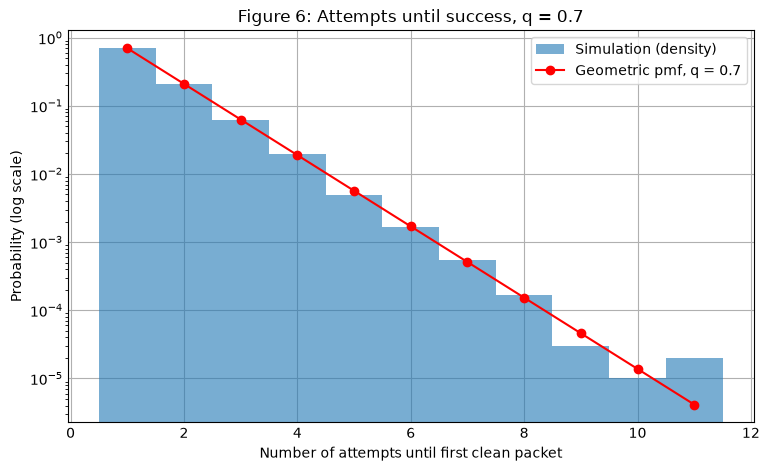

In [16]:
# Question 3: simulate 10^5 sequences with q=0.7 and plot Figure 6
q, n_seq = 0.7, 10 ** 5
X = ml.attempts_until_clean(n_seq, q, rng_6)

kmax = X.max()
k = np.arange(1, kmax + 1)
plt.figure(figsize = (7, 4))
plt.hist(X, bins=np.arange(0.5, kmax + 1.5, 1), density=True, alpha=0.6, label="Simulation (density)")
plt.plot(k, stats.geom.pmf(k, q), "ro-", label="Geometric pmf, q = 0.7")
plt.yscale("log")
plt.xlabel("Number of attempts until first clean packet")
plt.ylabel("Probability (log scale)")
plt.title("Figure 6: Attempts until success, q = 0.7")
plt.legend()
plt.show()

In [17]:
# Question 4: sample mean and variance vs the closed forms
mean_th, var_th = 1 / q, (1 - q) / q**2
mean_s, var_s = X.mean(), X.var(ddof=1)
se_mean = X.std(ddof=1) / np.sqrt(n_seq)

print(f"mean:     sample {mean_s:.4f}   theory {mean_th:.4f}   diff {mean_s - mean_th:+.2e}   SE {se_mean:.2e}")
print(f"variance: sample {var_s:.4f}   theory {var_th:.4f}   diff {var_s - var_th:+.2e}")

mean:     sample 1.4261   theory 1.4286   diff -2.46e-03   SE 2.47e-03
variance: sample 0.6089   theory 0.6122   diff -3.36e-03


In [18]:
# Question 5: memoryless property
print(f"{'(m,n)':8s} {'P(X>m+n | X>m)':>15s} {'P(X>n)':>9s} {'diff':>10s} {'SE':>9s} {'#cond':>7s}")
for m, n in [(1, 2), (3, 2), (5, 2)]:
    cond = X[X > m]
    p_hat = np.mean(cond > m + n)
    p_th = (1 - q) ** n
    se = np.sqrt(p_hat * (1 - p_hat) / len(cond))
    print(f"({m},{n})   {p_hat:15.4f} {p_th:9.4f} {p_hat - p_th:+10.2e} {se:9.2e} {len(cond):7d}")

(m,n)     P(X>m+n | X>m)    P(X>n)       diff        SE   #cond
(1,2)            0.0913    0.0900  +1.35e-03  1.67e-03   29842
(3,2)            0.0902    0.0900  +2.42e-04  5.49e-03    2726
(5,2)            0.0935    0.0900  +3.50e-03  1.86e-02     246


**Question 3 (Figure 6):** The histogram matches the geometric pmf pretty well. On the log scale it's a straight line, because each extra attempt multiplies the probability by 0.3.

**Question 4:** The sample mean was 1,4261 and the theory says 1.4286, so the difference is -2.46e-3 (standard error 2.47e-3, about 1 SE). The sample variance was 0.6089 and the theory says 0.6122, a difference of -3.36e-3.

**Question 5:** The count is bigger than k only if the first k attempts all fail, so $P(X > k) = (1-q)^k$. Then: $P(X > m+n \mid X > m) = P(X > m+n) / P(X > m) = (1-q)^{m+n} / (1-q)^m = (1-q)^n = P(X > n)$ 

For q=0.7 this is $0.3^2 = 0.09$ for all three pairs. The simulated values were 0.0913, 0.0902, and 0.0935, which differ from 0.09 by 0.8, 0.04, and 0.2 standard errors, so all three are withing one standard error. The (5,2) one is less accurate (SE 0.0186)because only 246 of the 100,000 sequences lasted past 5 attempts.

**Question 6:** In the model each attempt is independent, so earlier failures tell us nothing about the next one. The assumption that makes this true is that the noise on each attempt is independent. On a real radio link this isn't true, because interference and fading come in bursts. If it failed 5 times, the link is probably in a bad patch, so the 6th try is actually less likely to work.

## Step 7: Expectation, variance, and how fast estimates settle

### Question 1: Distribution cases and theoretical predictions

We study the Binomial packet error count with $ n=1000 $,
$ p=0.005 $, and the geometric attempt count with $ q=0.7 $.

Their theoretical means and variances are

$$
\mu_B=np=5,\qquad \sigma_B^2=np(1-p)=4.975,
$$

$$
\mu_G=\frac{1}{q}\approx1.428571,\qquad
\sigma_G^2=\frac{1-q}{q^2}\approx0.612245.
$$

For $ N $ independent samples, the running sample mean is

$$
\bar X_N=\frac{1}{N}\sum_{i=1}^{N}X_i.
$$

Its expectation is $E[\bar X_N]=\mu$. Independence gives

$$
\operatorname{Var}(\bar X_N)
=\frac{1}{N^2}\sum_{i=1}^{N}\sigma^2
=\frac{\sigma^2}{N}.
$$

Therefore,

$$
SE(\bar X_N)=\frac{\sigma}{\sqrt N}.
$$

We repeat each experiment 200 times independently, recording running
means at 30 logarithmically spaced checkpoints from 10 to 100,000 trials.
Only checkpoint means are retained between runs.

The shaded band shows the central 95% of the 200 estimates at each
checkpoint, using the 2.5th and 97.5th percentiles.

In [19]:
# Question 2 & 3
runs7 = 200
max_N7 = 100_000

checkpoints7 = np.unique(
    np.rint(np.logspace(1, 5, 30)).astype(int)
)

mu_bin7 = 1000 * 0.005
var_bin7 = 1000 * 0.005 * (1 - 0.005)

mu_geo7 = 1 / 0.7
var_geo7 = (1 - 0.7) / 0.7**2

# Retain only 200 x 30 checkpoint means per distribution.
bin_means7 = np.empty((runs7, len(checkpoints7)))
geo_means7 = np.empty_like(bin_means7)

# Independent streams for the two distributions.
rng_bin7, rng_geo7 = rng_7.spawn(2)

for run7 in range(runs7):
    samples7 = ml.packet_errors(
        max_N7, 1000, 0.005, rng_bin7
    )
    sums7 = np.cumsum(samples7, dtype=float)
    bin_means7[run7] = (
        sums7[checkpoints7 - 1] / checkpoints7
    )
    del samples7, sums7

    samples7 = ml.attempts_until_clean(
        max_N7, 0.7, rng_geo7
    )
    sums7 = np.cumsum(samples7, dtype=float)
    geo_means7[run7] = (
        sums7[checkpoints7 - 1] / checkpoints7
    )
    del samples7, sums7

print("Binomial stored shape:", bin_means7.shape)
print("Geometric stored shape:", geo_means7.shape)
print("Checkpoints:", checkpoints7)
print("Simulation completed.")

Binomial stored shape: (200, 30)
Geometric stored shape: (200, 30)
Checkpoints: [    10     14     19     26     36     49     67     92    127    174
    240    329    452    621    853   1172   1610   2212   3039   4175
   5736   7880  10826  14874  20434  28072  38566  52983  72790 100000]
Simulation completed.


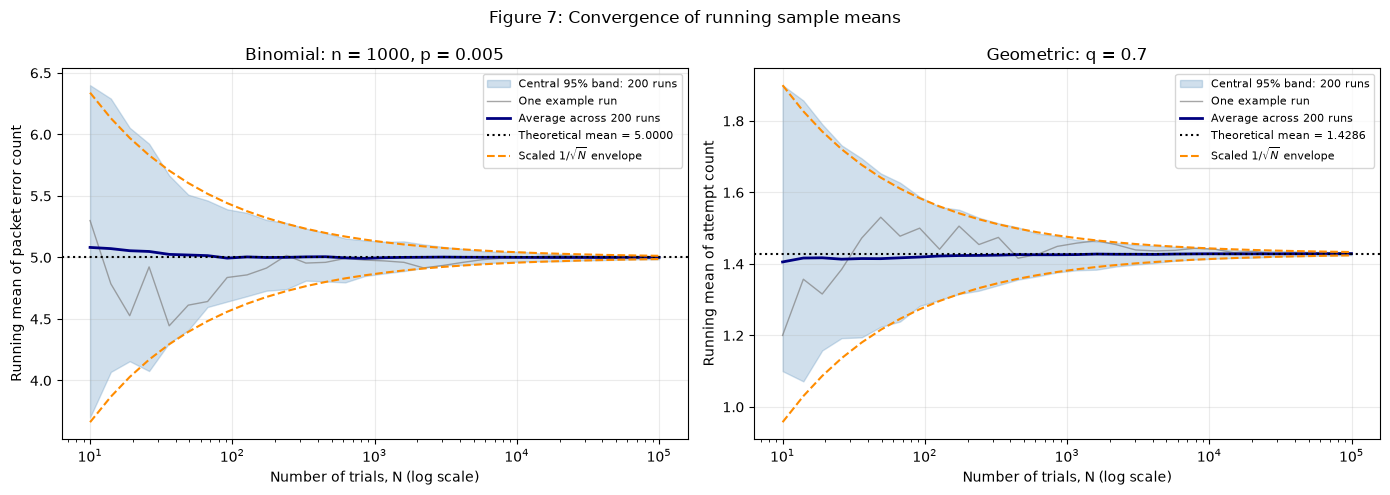

In [20]:
# Question 3 & 4
bin_low7, bin_high7 = np.percentile(
    bin_means7, [2.5, 97.5], axis=0
)
geo_low7, geo_high7 = np.percentile(
    geo_means7, [2.5, 97.5], axis=0
)

# Match the envelope to the band at the checkpoint nearest N = 1000.
anchor7 = np.argmin(np.abs(checkpoints7 - 1000))
anchor_N7 = checkpoints7[anchor7]

cases7 = [
    (
        bin_means7, bin_low7, bin_high7, mu_bin7,
        "Binomial: n = 1000, p = 0.005",
        "Running mean of packet error count"
    ),
    (
        geo_means7, geo_low7, geo_high7, mu_geo7,
        "Geometric: q = 0.7",
        "Running mean of attempt count"
    ),
]

# Use a local style so this figure does not change teammates' plots.
with plt.style.context("default"):
    fig7, axes7 = plt.subplots(1, 2, figsize=(14, 5))

    for ax7, case7 in zip(axes7, cases7):
        means7, low7, high7, mu7, title7, ylabel7 = case7

        halfwidth7 = (
            high7[anchor7] - low7[anchor7]
        ) / 2

        envelope7 = halfwidth7 * np.sqrt(
            anchor_N7 / checkpoints7
        )

        ax7.fill_between(
            checkpoints7, low7, high7,
            color="steelblue", alpha=0.25,
            label="Central 95% band: 200 runs"
        )

        ax7.plot(
            checkpoints7, means7[0],
            color="gray", linewidth=1, alpha=0.7,
            label="One example run"
        )

        ax7.plot(
            checkpoints7, means7.mean(axis=0),
            color="navy", linewidth=2,
            label="Average across 200 runs"
        )

        ax7.axhline(
            mu7, color="black", linestyle=":",
            label=f"Theoretical mean = {mu7:.4f}"
        )

        ax7.plot(
            checkpoints7, mu7 + envelope7,
            color="darkorange", linestyle="--",
            label=r"Scaled $1/\sqrt{N}$ envelope"
        )

        ax7.plot(
            checkpoints7, mu7 - envelope7,
            color="darkorange", linestyle="--"
        )

        ax7.set_xscale("log")
        ax7.set_xlabel("Number of trials, N (log scale)")
        ax7.set_ylabel(ylabel7)
        ax7.set_title(title7)
        ax7.grid(alpha=0.25)
        ax7.legend(fontsize=8)

    fig7.suptitle("Figure 7: Convergence of running sample means")
    fig7.tight_layout()
    plt.show()

### Explanation of Figure 7

Increasing the number of trials reduces the spread of the running
sample means around the theoretical values of 5 and approximately
1.4286. Individual runs fluctuate, while the average across 200 runs
is smoother.

The empirical bands approximately follow the narrowing
$1/\sqrt N$ envelopes, consistent with the standard-error formula.
A tenfold increase in sample size reduces the theoretical standard
error by a factor of $\sqrt{10}$, rather than by a factor of ten.

The bands are pointwise central 95% ranges across the simulated runs; which means that
they do not guarantee that an entire running-mean trajectory stays
inside the band.

In [21]:
# Question 5
tolerance7 = 0.01 * mu_bin7
target_low7 = mu_bin7 - tolerance7
target_high7 = mu_bin7 + tolerance7

inside7 = (
    (bin_low7 >= target_low7)
    & (bin_high7 <= target_high7)
)

# Find a checkpoint where the band fits and remains inside
# at every later tested checkpoint.
stays_inside7 = np.logical_and.accumulate(
    inside7[::-1]
)[::-1]

valid7 = np.flatnonzero(stays_inside7)

print("BINOMIAL PRECISION TABLE")
print(f"{'N':>8} {'Band lower':>13} {'Band upper':>13} {'Within 1%':>12}")

for N7, low7, high7, fits7 in zip(
    checkpoints7, bin_low7, bin_high7, inside7
):
    print(
        f"{N7:8d} {low7:13.5f} {high7:13.5f} "
        f"{str(bool(fits7)):>12}"
    )

print(f"\nTarget interval: [{target_low7:.2f}, {target_high7:.2f}]")

if valid7.size:
    chosen7 = valid7[0]
    print(
        "First tested checkpoint that fits and stays inside:",
        int(checkpoints7[chosen7])
    )
    print(
        f"Band there: [{bin_low7[chosen7]:.5f}, "
        f"{bin_high7[chosen7]:.5f}]"
    )
else:
    print("No checkpoint met the sustained-band criterion.")

theory_N7 = int(np.ceil(
    1.96**2 * var_bin7 / tolerance7**2
))
print("Approximate normal-theory requirement:", theory_N7)

# Numerical evidence for convergence at N = 100,000.
print("\nFINAL MEAN COMPARISONS")

for name7, means7, mu7, variance7 in [
    ("Binomial", bin_means7, mu_bin7, var_bin7),
    ("Geometric", geo_means7, mu_geo7, var_geo7),
]:
    final7 = means7[:, -1]
    estimate7 = final7.mean()

    # Uncertainty of the average across 200 independent runs.
    average_se7 = np.sqrt(
        variance7 / (runs7 * max_N7)
    )

    # Expected spread among individual runs.
    one_run_se7 = np.sqrt(variance7 / max_N7)
    observed_sd7 = final7.std(ddof=1)

    print(f"\n{name7}:")
    print(f"  Theory mean:                 {mu7:.7f}")
    print(f"  Average final mean:          {estimate7:.7f}")
    print(f"  Difference:                  {estimate7 - mu7:.7f}")
    print(f"  SE of average across runs:   {average_se7:.7f}")
    print(f"  Observed SD across runs:     {observed_sd7:.7f}")
    print(f"  Theoretical SE of one run:   {one_run_se7:.7f}")

BINOMIAL PRECISION TABLE
       N    Band lower    Band upper    Within 1%
      10       3.70000       6.40000        False
      14       4.06964       6.29107        False
      19       4.15658       6.05395        False
      26       4.07692       5.92404        False
      36       4.30486       5.66667        False
      49       4.40816       5.51020        False
      67       4.59701       5.46269        False
      92       4.64103       5.39130        False
     127       4.68504       5.36240        False
     174       4.72974       5.30474        False
     240       4.74167       5.27958        False
     329       4.81140       5.23419        False
     452       4.80520       5.19967        False
     621       4.79702       5.15479        False
     853       4.84856       5.13851        False
    1172       4.87001       5.12735        False
    1610       4.88929       5.13051        False
    2212       4.91490       5.10596        False
    3039       4.93745   

### Question 5: Result and theoretical cross-check

The Binomial mean is 5, so the target interval is

$$
5\pm0.01(5)=[4.95,5.05].
$$

We use the first tested checkpoint where the entire empirical central
95% band fits inside this interval and remains inside at all later
tested checkpoints. The output above reports the checkpoint and its
band boundaries.

For a theoretical cross-check, a normal approximation gives

$$
1.96\sqrt{\frac{4.975}{N}}\le0.05.
$$

Squaring and rearranging,

$$
N\ge\frac{1.96^2(4.975)}{0.05^2}\approx7645.
$$

The empirical threshold doesn't need to equal this value because the band
is estimated from 200 runs and evaluated only at discrete checkpoints.
The result describes approximately 95% accuracy across repeated
experiments, which is not a guarantee for every experiment.
In our simulation, the first tested checkpoint where the central
95% band fits within [4.95, 5.05] and remains inside at subsequent
checkpoints is N = 7,880. Its band is [4.96063, 5.04609].
This is close to the approximate theoretical requirement of
7,645 trials!

## Step 8: Putting it together, the throughput of the link

In [22]:
# call rng_8